# 03. Entrenamiento de modelos y diagnóstico de sobreajuste y subajuste

Tres algoritmos con fundamentos distintos, una línea base de una sola variable y el diagnóstico de sobreajuste y subajuste de la Semana 3 (tracking por iteración, curvas A, B, C y D, diagnóstico cuantitativo y estrategias de mejora).

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import cargar_config, ruta, guardar_json, leer_json
CFG = cargar_config()
FIG = ruta(CFG["rutas"]["figuras"]); MET = ruta(CFG["rutas"]["metricas"])
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
C1, C2, C3, C4 = "#1F3A5F", "#C0504D", "#7F7F7F", "#E1A93B"
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIG / nombre, bbox_inches="tight"); plt.show()
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss
from src.data_processing import FEATURES
from src.model import crear_gradient_boosting, crear_random_forest, crear_regresion_logistica
from src.evaluate import cargar_particiones
train, test = cargar_particiones(CFG)
Xtr, ytr, Xte, yte = train[FEATURES], train.no_show, test[FEATURES], test.no_show

In [2]:
modelos = {'Regresión logística': crear_regresion_logistica(), 'Random Forest': crear_random_forest(42), 'Gradient Boosting': crear_gradient_boosting(42)}
filas, probs = [], {}
for n, m in modelos.items():
    m.fit(Xtr, ytr); p = m.predict_proba(Xte)[:,1]; probs[n] = p
    filas.append({'modelo': n, 'AUC-ROC': roc_auc_score(yte,p), 'AUC-PR': average_precision_score(yte,p), 'Brier': brier_score_loss(yte,p), 'AUC entrenamiento': roc_auc_score(ytr, m.predict_proba(Xtr)[:,1])})
base = crear_regresion_logistica().fit(Xtr[['lead_time_days']], ytr); pb = base.predict_proba(Xte[['lead_time_days']])[:,1]
filas.append({'modelo':'Referencia: solo antelación','AUC-ROC':roc_auc_score(yte,pb),'AUC-PR':average_precision_score(yte,pb),'Brier':brier_score_loss(yte,pb)})
filas.append({'modelo':'Sin información','AUC-ROC':0.5,'AUC-PR':yte.mean(),'Brier':brier_score_loss(yte, np.full(len(yte), ytr.mean()))})
tabla = pd.DataFrame(filas).round(4); tabla.to_csv(MET/'modelos_iniciales.csv', index=False); tabla

,modelo,AUC-ROC,AUC-PR,Brier,AUC entrenamiento
0,Regresión logística,0.6655,0.3053,0.1542,0.6632
1,Random Forest,0.7338,0.3660,0.1441,0.7486
2,Gradient Boosting,0.7397,0.3757,0.1426,0.7745
3,Referencia: solo antelación,0.7021,0.3111,0.1561,NaN
4,Sin información,0.5000,0.2019,0.1612,NaN


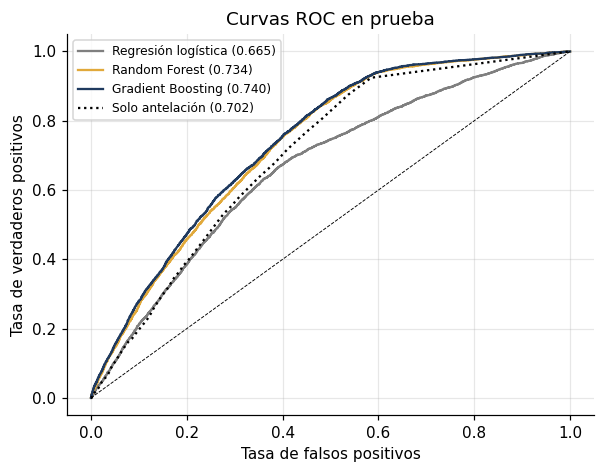

In [3]:
fig, ax = plt.subplots(figsize=(5.6,4.4))
for (n,p),c in zip(probs.items(), [C3,C4,C1]):
    f,t,_ = roc_curve(yte,p); ax.plot(f,t,color=c,label=f'{n} ({roc_auc_score(yte,p):.3f})')
f,t,_ = roc_curve(yte,pb); ax.plot(f,t,':',color='k',label=f'Solo antelación ({roc_auc_score(yte,pb):.3f})')
ax.plot([0,1],[0,1],'k--',lw=.6); ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(fontsize=8); ax.set_title('Curvas ROC en prueba')
guardar('09_roc.png')

## Sobreajuste y subajuste
Random Forest con tres profundidades: la brecha entre AUC de entrenamiento y prueba revela el sobreajuste.

In [4]:
rows = []
for nombre, kw in [('max_depth=3', dict(max_depth=3, min_samples_leaf=50, n_estimators=200)), ('max_depth=8', dict(max_depth=8, min_samples_leaf=20)), ('sin límite', dict(max_depth=None, min_samples_leaf=1, n_estimators=200))]:
    m = crear_random_forest(42, **kw).fit(Xtr, ytr)
    rows.append({'configuración': nombre, 'AUC entrenamiento': roc_auc_score(ytr, m.predict_proba(Xtr)[:,1]), 'AUC prueba': roc_auc_score(yte, m.predict_proba(Xte)[:,1])})
sa = pd.DataFrame(rows); sa['brecha'] = sa['AUC entrenamiento'] - sa['AUC prueba']; sa.round(3)

,configuración,AUC entrenamiento,AUC prueba,brecha
0,max_depth=3,0.711,0.710,0.001
1,max_depth=8,0.749,0.734,0.015
2,sin límite,0.999,0.701,0.298


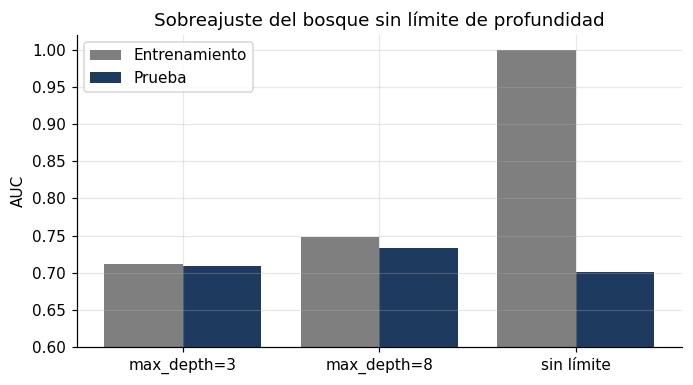

In [5]:
x = np.arange(len(sa)); fig, ax = plt.subplots(figsize=(6.4,3.6))
ax.bar(x-.2, sa['AUC entrenamiento'], .4, color=C3, label='Entrenamiento'); ax.bar(x+.2, sa['AUC prueba'], .4, color=C1, label='Prueba')
ax.set_xticks(x, sa['configuración']); ax.set_ylim(.6,1.02); ax.set_ylabel('AUC'); ax.legend(); ax.set_title('Sobreajuste del bosque sin límite de profundidad')
guardar('10_sobreajuste.png')

## Diagnóstico de sobreajuste y subajuste (actividad de la Semana 3)

Se aplica al modelo del proyecto la metodología de la Semana 3: tracking de métricas por iteración, curvas de entrenamiento y validación (A: pérdida; B: exactitud y AUC), curvas por tamaño de dataset (C) y por hiperparámetro (D), diagnóstico cuantitativo con umbrales explícitos y estrategias de mejora evaluadas antes y después.

**Validación:** 20% del conjunto de entrenamiento separado **por paciente** (la prueba no se usa). Código reutilizable: `src/diagnosis.py`.

In [6]:
from sklearn.model_selection import StratifiedGroupKFold
from src.diagnosis import seguir_boosting, cuantificar, diagnosticar, curva_aprendizaje, curva_validacion, umbrales_dict
a, b = next(StratifiedGroupKFold(5, shuffle=True, random_state=7).split(train, train.no_show, train.PatientId))
Xa, ya, Xb, yb = Xtr.iloc[a], ytr.iloc[a], Xtr.iloc[b], ytr.iloc[b]
REGIMENES = {
    'Complejo sin regularización': dict(learning_rate=0.1, max_depth=None, max_leaf_nodes=255, min_samples_leaf=1, max_iter=300),
    'Muy simple (tocones, tasa 0.01)': dict(learning_rate=0.01, max_depth=1, max_iter=100),
    'Configuración final': dict(learning_rate=0.1, max_depth=5, min_samples_leaf=100, max_iter=100)}
REG = {n: seguir_boosting(crear_gradient_boosting(42, **p).fit(Xa, ya), Xa, ya, Xb, yb, n, cada=5) for n, p in REGIMENES.items()}
prev = ya.mean(); filas = []
for n, r in REG.items():
    q = cuantificar(r, prev); q['diagnostico'], q['justificacion'] = diagnosticar(q); filas.append(q)
DIAG = pd.DataFrame(filas); print('umbrales:', umbrales_dict())
DIAG[['modelo','mejor_iteracion','train_loss_final','val_loss_final','brecha_final','subida_val_pct','ratio_sin_informacion','train_auc_final','val_auc_final','diagnostico']].round(4)

umbrales: {'brecha_pequena': 0.02, 'brecha_grande': 0.05, 'subida_val': 0.02, 'ratio_subajuste': 0.9}


,modelo,mejor_iteracion,train_loss_final,val_loss_final,brecha_final,subida_val_pct,ratio_sin_informacion,train_auc_final,val_auc_final,diagnostico
0,Complejo sin regularización,25,0.2116,0.4800,0.2684,8.3901,0.4206,0.9906,0.7101,Overfitting
1,"Muy simple (tocones, tasa 0.01)",100,0.4649,0.4628,-0.0020,0.0000,0.9241,0.6873,0.6896,Underfitting
2,Configuración final,95,0.4286,0.4384,0.0098,0.0053,0.8520,0.7598,0.7383,Óptimo


In [7]:
for _, f in DIAG.iterrows(): print(f"{f['modelo']}: {f['diagnostico']} ({f['justificacion']})")

Complejo sin regularización: Overfitting (val_loss sube 8.4% desde su mínimo (iteración 25) y la brecha final es 0.268)
Muy simple (tocones, tasa 0.01): Underfitting (train_loss = 92% de la pérdida sin información y brecha pequeña (-0.002))
Configuración final: Óptimo (brecha 0.010 y val_loss a 0.0% de su mínimo)


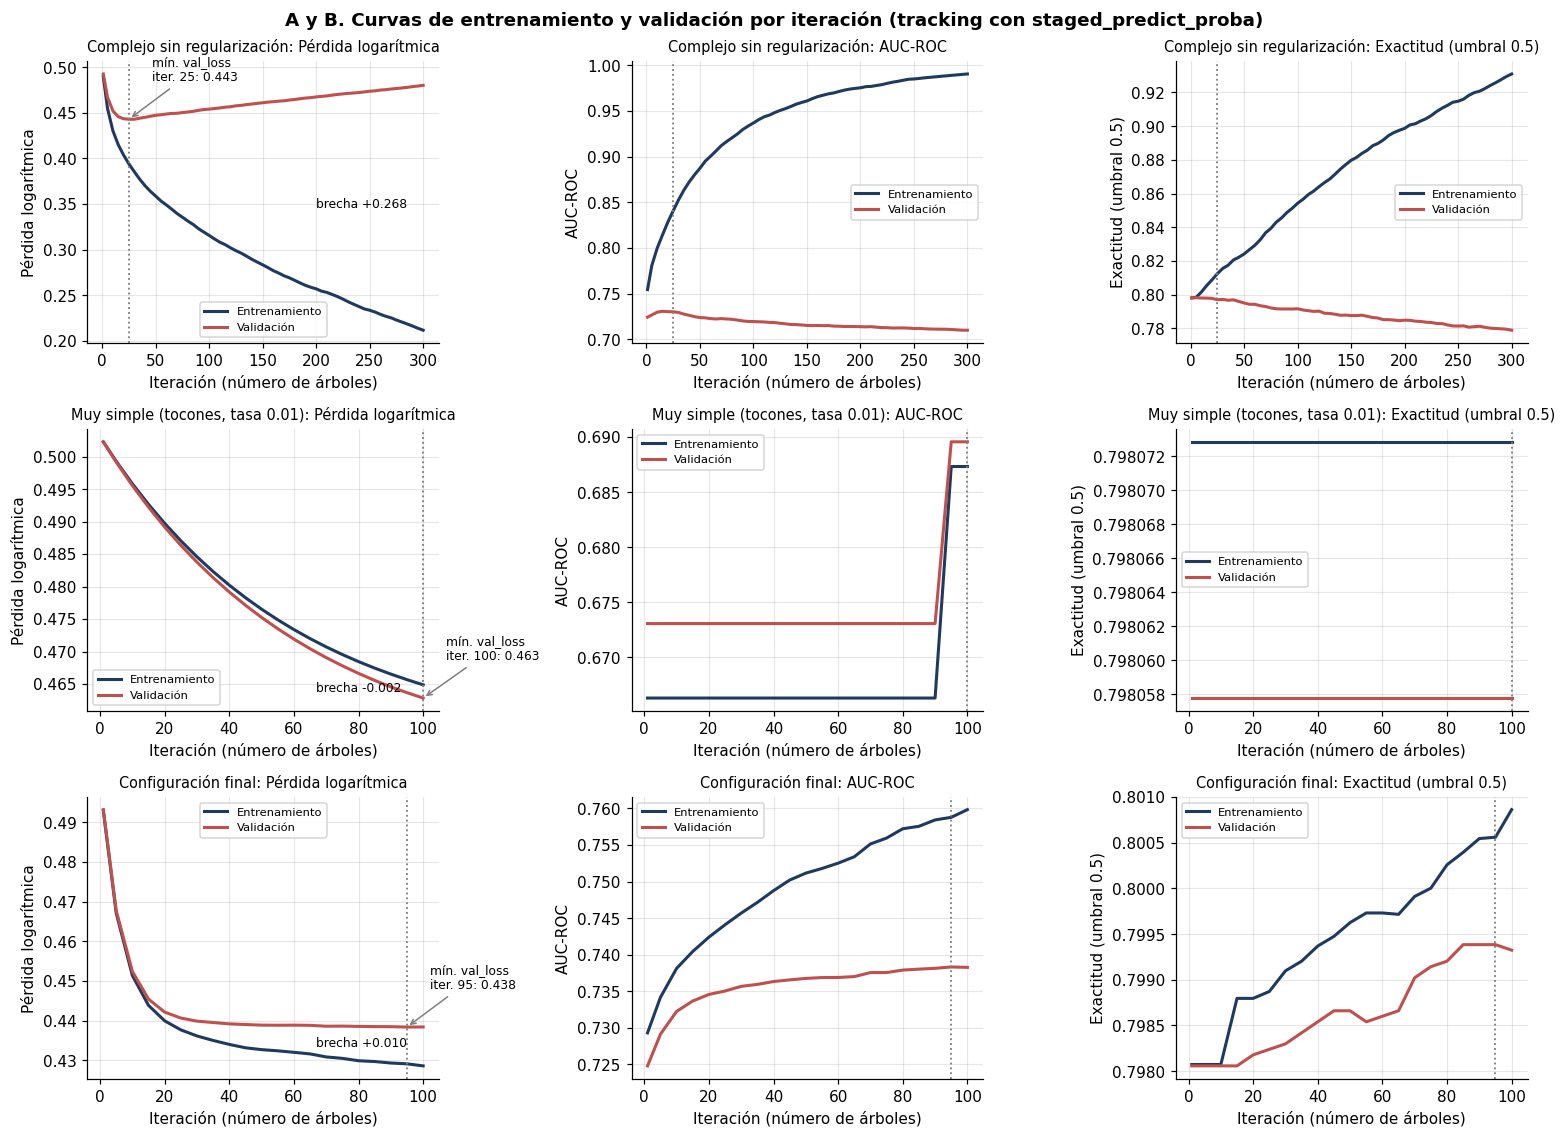

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10.5))
for fila, (n, r) in zip(axes, REG.items()):
    d = r.tabla(); mejor = int(d.loc[d.val_loss.idxmin(), 'iteracion'])
    for ax, m, et in zip(fila, ['loss','auc','acc'], ['Pérdida logarítmica','AUC-ROC','Exactitud (umbral 0.5)']):
        ax.plot(d.iteracion, d[f'train_{m}'], color=C1, lw=2, label='Entrenamiento'); ax.plot(d.iteracion, d[f'val_{m}'], color=C2, lw=2, label='Validación')
        ax.axvline(mejor, color=C3, ls=':', lw=1.2)
        if m == 'loss':
            y0 = d.loc[d.iteracion==mejor, 'val_loss'].iloc[0]; ax.annotate(f'mín. val_loss\niter. {mejor}: {y0:.3f}', (mejor, y0), xytext=(15, 25), textcoords='offset points', fontsize=8, arrowprops=dict(arrowstyle='->', color=C3))
            ultimo = d.iloc[-1]; ax.annotate(f"brecha {ultimo.val_loss-ultimo.train_loss:+.3f}", (ultimo.iteracion, (ultimo.val_loss+ultimo.train_loss)/2), xytext=(-70, 0), textcoords='offset points', fontsize=8)
        ax.ticklabel_format(axis='y', useOffset=False, style='plain'); ax.set_title(f'{n}: {et}', fontsize=9.5); ax.set_xlabel('Iteración (número de árboles)'); ax.set_ylabel(et); ax.legend(fontsize=7.5)
fig.suptitle('A y B. Curvas de entrenamiento y validación por iteración (tracking con staged_predict_proba)', fontweight='bold')
guardar('21_curvas_entrenamiento_validacion.png')

### C. Curvas de aprendizaje por tamaño del conjunto de entrenamiento
CV de 3 pliegues agrupada por paciente, AUC como métrica.

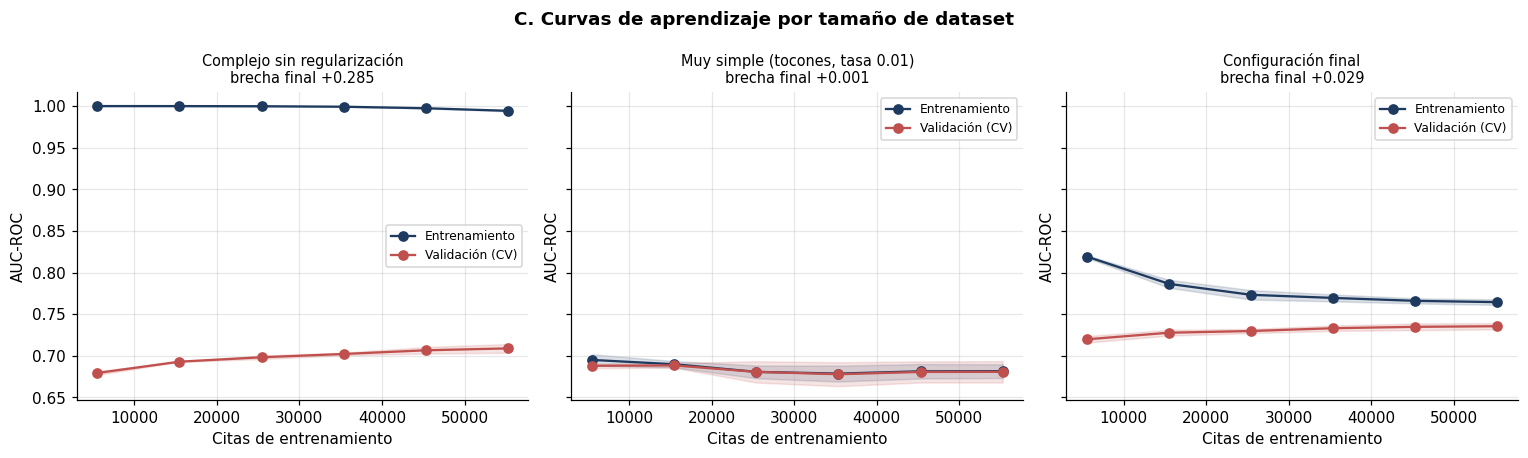

,val_auc_10%,val_auc_100%,brecha_final
Complejo sin regularización,0.6793,0.7089,0.2854
"Muy simple (tocones, tasa 0.01)",0.6880,0.6807,0.0008
Configuración final,0.7198,0.7355,0.0289


In [9]:
LC = {n: curva_aprendizaje(crear_gradient_boosting(42, **p), Xtr, ytr, train.PatientId) for n, p in REGIMENES.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (n, lc) in zip(axes, LC.items()):
    for col, c, et in [('train', C1, 'Entrenamiento'), ('val', C2, 'Validación (CV)')]:
        ax.plot(lc.n, lc[col], 'o-', color=c, label=et); ax.fill_between(lc.n, lc[col]-lc[f'{col}_de'], lc[col]+lc[f'{col}_de'], color=c, alpha=.15)
    ax.set_title(f"{n}\nbrecha final {lc.train.iloc[-1]-lc.val.iloc[-1]:+.3f}", fontsize=9.5); ax.set_xlabel('Citas de entrenamiento'); ax.set_ylabel('AUC-ROC'); ax.legend(fontsize=8)
fig.suptitle('C. Curvas de aprendizaje por tamaño de dataset', fontweight='bold'); guardar('22_curvas_aprendizaje_tamano.png')
pd.DataFrame({n: {'val_auc_10%': lc.val.iloc[0], 'val_auc_100%': lc.val.iloc[-1], 'brecha_final': lc.train.iloc[-1]-lc.val.iloc[-1]} for n, lc in LC.items()}).T.round(4)

### D. Curvas de validación por hiperparámetro

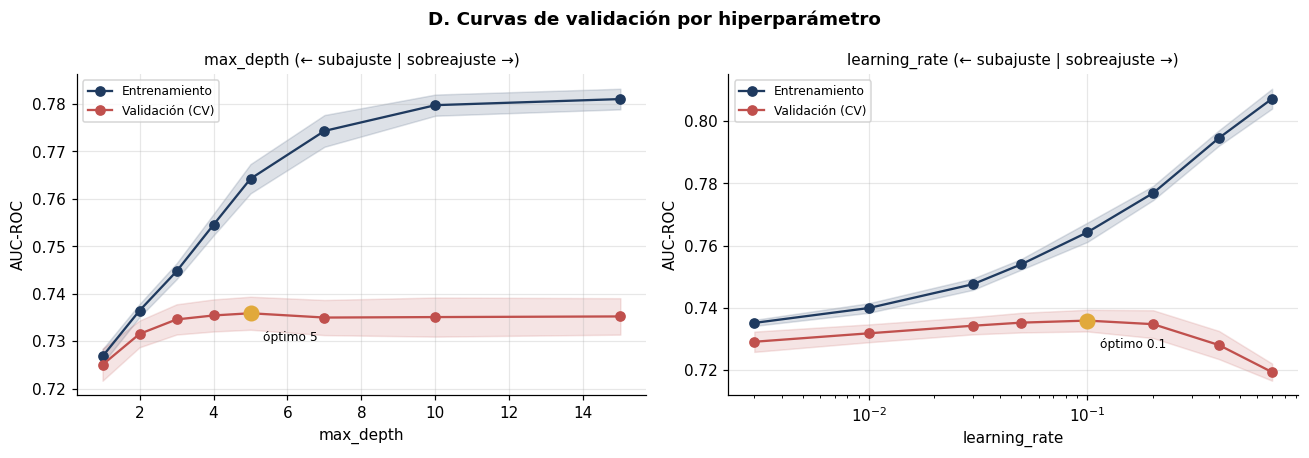

In [10]:
base = dict(learning_rate=0.1, max_depth=5, min_samples_leaf=100, max_iter=100)
VC_d = curva_validacion(crear_gradient_boosting(42, **{k: v for k, v in base.items() if k != 'max_depth'}), Xtr, ytr, train.PatientId, 'max_depth', [1, 2, 3, 4, 5, 7, 10, 15])
VC_l = curva_validacion(crear_gradient_boosting(42, **{k: v for k, v in base.items() if k != 'learning_rate'}), Xtr, ytr, train.PatientId, 'learning_rate', [0.003, 0.01, 0.03, 0.05, 0.1, 0.2, 0.4, 0.7])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, vc, et, log in [(axes[0], VC_d, 'max_depth', False), (axes[1], VC_l, 'learning_rate', True)]:
    for col, c, e in [('train', C1, 'Entrenamiento'), ('val', C2, 'Validación (CV)')]:
        ax.plot(vc.valor, vc[col], 'o-', color=c, label=e); ax.fill_between(vc.valor, vc[col]-vc[f'{col}_de'], vc[col]+vc[f'{col}_de'], color=c, alpha=.15)
    i = vc.val.idxmax(); ax.scatter(vc.valor[i], vc.val[i], s=90, color=C4, zorder=5); ax.annotate(f'óptimo {vc.valor[i]:g}', (vc.valor[i], vc.val[i]), xytext=(8, -18), textcoords='offset points', fontsize=8)
    if log: ax.set_xscale('log')
    ax.set_xlabel(et); ax.set_ylabel('AUC-ROC'); ax.legend(fontsize=8); ax.set_title(f'{et} (← subajuste | sobreajuste →)', fontsize=10)
fig.suptitle('D. Curvas de validación por hiperparámetro', fontweight='bold'); guardar('23_curvas_validacion_hiperparametros.png')

### Estrategias de mejora aplicadas al modelo con sobreajuste y al modelo con subajuste

In [11]:
mejor_it = int(REG['Complejo sin regularización'].mejor()['iteracion'])
ESTR = {
    'Base con sobreajuste': REGIMENES['Complejo sin regularización'],
    'E1 early stopping (grupo de validación)': {**REGIMENES['Complejo sin regularización'], 'max_iter': mejor_it},
    'E2 regularización (L2=10, hoja mínima 200)': {**REGIMENES['Complejo sin regularización'], 'l2_regularization': 10.0, 'min_samples_leaf': 200},
    'E3 menor complejidad (profundidad 5, hoja 100, 100 árboles)': REGIMENES['Configuración final'],
    'Base con subajuste': REGIMENES['Muy simple (tocones, tasa 0.01)'],
    'U1 más capacidad y mayor tasa (= configuración final)': REGIMENES['Configuración final']}
filas = []
for n, p in ESTR.items():
    r = seguir_boosting(crear_gradient_boosting(42, **p).fit(Xa, ya), Xa, ya, Xb, yb, n, cada=5)
    q = cuantificar(r, prev); q['diagnostico'] = diagnosticar(q)[0]; filas.append(q)
EST = pd.DataFrame(filas); EST[['modelo','train_loss_final','val_loss_final','brecha_final','val_auc_final','diagnostico']].round(4)

,modelo,train_loss_final,val_loss_final,brecha_final,val_auc_final,diagnostico
0,Base con sobreajuste,0.2116,0.4800,0.2684,0.7101,Overfitting
1,E1 early stopping (grupo de validación),0.3938,0.4428,0.0491,0.7302,Overfitting leve
2,"E2 regularización (L2=10, hoja mínima 200)",0.3344,0.4614,0.1270,0.7198,Overfitting
3,"E3 menor complejidad (profundidad 5, hoja 100,...",0.4286,0.4384,0.0098,0.7383,Óptimo
4,Base con subajuste,0.4649,0.4628,-0.0020,0.6896,Underfitting
5,U1 más capacidad y mayor tasa (= configuración...,0.4286,0.4384,0.0098,0.7383,Óptimo


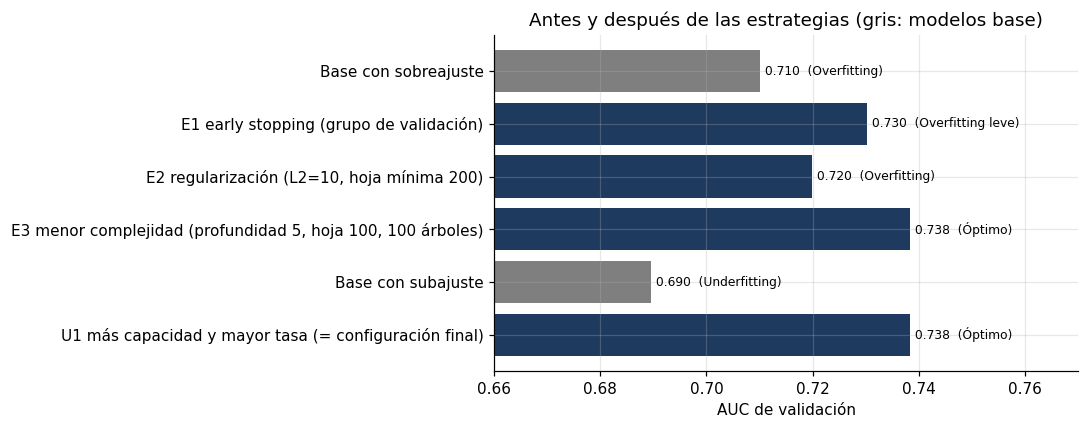

PosixPath('/home/claude/repo/priorizacion-visitas-ia/results/metrics/diagnostico_ajuste.json')

In [12]:
fig, ax = plt.subplots(figsize=(10, 4)); cols = [C3, C1, C1, C1, C3, C1]
ax.barh(EST.modelo[::-1], EST.val_auc_final[::-1], color=cols[::-1])
for i, (v, d) in enumerate(zip(EST.val_auc_final[::-1], EST.diagnostico[::-1])): ax.text(v + .001, i, f'{v:.3f}  ({d})', va='center', fontsize=8)
ax.set_xlim(.66, .77); ax.set_xlabel('AUC de validación'); ax.set_title('Antes y después de las estrategias (gris: modelos base)')
guardar('24_estrategias_diagnostico.png')
guardar_json({'diagnostico': DIAG.to_dict(orient='records'), 'estrategias': EST.to_dict(orient='records'), 'umbrales': umbrales_dict(),
             'curvas_aprendizaje': {n: lc.to_dict(orient='records') for n, lc in LC.items()},
             'validacion_max_depth': VC_d.to_dict(orient='records'), 'validacion_learning_rate': VC_l.to_dict(orient='records')}, MET/'diagnostico_ajuste.json')

## Conclusión
Gradient Boosting es el mejor en las tres métricas, aunque solo supera por ~0.04 de AUC al modelo que únicamente usa la antelación. La regresión logística subajusta (queda por debajo de la referencia) porque la relación con la antelación no es lineal. El modelo inicial se guarda como `models/model_v1.pkl` (lo hace `src/train.py`).